# 04｜ViViT 因子的 CNE5S + 20 日反转暴露分析与残差化

请使用 `ViT Factor Eval (Alphalens/Pyfolio)` 内核。本 Notebook 把“诊断源因子暴露”和“生成残差 run”明确分开：

1. 先按 `SOURCE_PREDICTION_COLUMN` 读取源信号，检查 CNE5S/反转覆盖，并计算该信号、9 个 CNE5S 风格和 20 日反转共 11 个变量的横截面 Pearson；
2. 在生成任何残差之前展示相关性汇总、11×11 热力图和日度时间序列；
3. 仅当 `GENERATE_RESIDUAL_RUN=True` 时，才以 10 个风险连续变量和行业固定效应做等权 OLS，生成可供 Notebook03 回测的残差 run。

20 日反转定义为 `-(adjclose(T) / adjclose(T-20个SSE交易日) - 1)`，只接受精确 T 与 T−20 复权价，不前向填充、不使用未来数据。残差保持原始尺度，不再做逐日 Z-score。


## 步骤 1：设置源 run、数据路径与残差生成开关

`SOURCE_PREDICTION_COLUMN` 决定相关性分析和残差化共同使用哪一列。对于 `gate_neutral`，原始模型输出应选 `prediction_ensemble_unprojected`；`prediction_ensemble` 是严格投影后的正式分数。

默认 `GENERATE_RESIDUAL_RUN=False`，此时整个 Notebook 只做只读诊断，不创建、覆盖或删除任何残差预测、factor evaluation 或实验报告。

只有把它显式改成 `True`，最后一个单元才会调用残差构建。若同名派生 run 已存在但签名不同，还必须同时设置 `OVERWRITE_EXISTING_DERIVED_RUN=True`；覆盖采用 staging 验证与原子替换，成功后旧回测产物会失效并被移除。


In [1]:
from pathlib import Path
import sys
from IPython.display import display

CURRENT_DIR = Path.cwd().resolve()
VIVIT_DIR = CURRENT_DIR if (CURRENT_DIR / "stage09_barra_postprocess.py").exists() else CURRENT_DIR / "ViViT"
if not (VIVIT_DIR / "stage09_barra_postprocess.py").exists():
    raise FileNotFoundError("无法定位 ViViT/stage09_barra_postprocess.py")
if str(VIVIT_DIR) not in sys.path:
    sys.path.insert(0, str(VIVIT_DIR))

from stage09_barra_postprocess import SOURCE_FACTOR_COLUMNS

VIVIT_DATA_ROOT = VIVIT_DIR / "data"
CNE5S_PATH = VIVIT_DIR.parent / "CNE5S.parquet"
EOD_PATH = VIVIT_DIR.parent / "Wind" / "ASHAREEODPRICES.parquet"
CALENDAR_PATH = VIVIT_DIR.parent / "Wind" / "ASHARECALENDAR.parquet"

# 可选：任意合法的源预测 run 名称。
SOURCE_RUN_NAME = "dual_tower"
# 可选：prediction_ensemble、prediction_ensemble_raw、prediction_ensemble_unprojected、
# prediction_ensemble_projected、prediction_ensemble_alpha、prediction_ensemble_style、
# prediction_ensemble_total_return。No.6 默认主列等于 Alpha，也可分别分析三类分数。
# gate_neutral 的原始模型输出使用 prediction_ensemble_unprojected。
SOURCE_PREDICTION_COLUMN = "prediction_ensemble"
# 可选：任意不等于 SOURCE_RUN_NAME 的合法派生 run 名称。
RESIDUAL_RUN_NAME = f"{SOURCE_RUN_NAME}_barra_residual"
# 可选：0.0～1.0；CNE5S 精确同日匹配率低于该阈值时立即报错。
MINIMUM_MATCH_RATE = 0.999
# 可选：False（仅诊断，不生成残差，默认）或 True（生成/复用残差 run）。
GENERATE_RESIDUAL_RUN = True
# 可选：False（禁止覆盖，默认）或 True（允许替换签名不同的旧派生 run）；
# 仅在 GENERATE_RESIDUAL_RUN=True 时生效。
OVERWRITE_EXISTING_DERIVED_RUN = True

if SOURCE_PREDICTION_COLUMN not in SOURCE_FACTOR_COLUMNS:
    raise ValueError(
        f"未知 SOURCE_PREDICTION_COLUMN：{SOURCE_PREDICTION_COLUMN!r}；"
        f"可选 {SOURCE_FACTOR_COLUMNS}"
    )
if not isinstance(GENERATE_RESIDUAL_RUN, bool):
    raise TypeError("GENERATE_RESIDUAL_RUN 必须是 bool")
if not isinstance(OVERWRITE_EXISTING_DERIVED_RUN, bool):
    raise TypeError("OVERWRITE_EXISTING_DERIVED_RUN 必须是 bool")

print({
    "源run": SOURCE_RUN_NAME,
    "源预测列": SOURCE_PREDICTION_COLUMN,
    "残差派生run": RESIDUAL_RUN_NAME,
    "本次是否生成残差": GENERATE_RESIDUAL_RUN,
    "显式覆盖授权": OVERWRITE_EXISTING_DERIVED_RUN,
    "CNE5S": str(CNE5S_PATH),
    "Wind复权价": str(EOD_PATH),
    "SSE交易日历": str(CALENDAR_PATH),
    "最低CNE5S同日匹配率": MINIMUM_MATCH_RATE,
    "反转公式": "-(adjclose(T)/adjclose(T-20个SSE交易日)-1)",
    "回归口径": "9 个 CNE5S 风格 + 20 日反转 + 行业固定效应",
    "反转缺失策略": "有效值日度Z-score(ddof=0)，缺失填0",
    "残差尺度": "原始 OLS 残差，不重新 Z-score",
})


{'源run': 'dual_tower', '源预测列': 'prediction_ensemble', '残差派生run': 'dual_tower_barra_residual', '本次是否生成残差': True, '显式覆盖授权': True, 'CNE5S': '/root/autodl-tmp/CNE5S.parquet', 'Wind复权价': '/root/autodl-tmp/Wind/ASHAREEODPRICES.parquet', 'SSE交易日历': '/root/autodl-tmp/Wind/ASHARECALENDAR.parquet', '最低CNE5S同日匹配率': 0.999, '反转公式': '-(adjclose(T)/adjclose(T-20个SSE交易日)-1)', '回归口径': '9 个 CNE5S 风格 + 20 日反转 + 行业固定效应', '反转缺失策略': '有效值日度Z-score(ddof=0)，缺失填0', '残差尺度': '原始 OLS 残差，不重新 Z-score'}


## 步骤 2：只读检查覆盖并计算源因子相关性

本步骤不会写入任何预测或质量目录。相关性和后续残差化严格使用同一个 `SOURCE_PREDICTION_COLUMN`。CNE5S 只允许 `trade_date + assetid` 精确同日匹配；反转只允许 SSE 日历上的精确 T/T−20 复权价，不按个股有效观测回退。相关性统一使用 `barra_matched & reversal_20d_valid` 的完整同日样本。


In [2]:
from stage09_barra_postprocess import (
    CORRELATION_COLUMNS, MATRIX_COLUMNS, MATRIX_LABELS,
    REGRESSION_COLUMNS, STYLE_COLUMNS, STYLE_LABELS,
    REVERSAL_COLUMN, analyze_barra_exposures,
)

analysis = analyze_barra_exposures(
    source_run_name=SOURCE_RUN_NAME,
    cne5s_path=CNE5S_PATH,
    vivit_data_root=VIVIT_DATA_ROOT,
    minimum_match_rate=MINIMUM_MATCH_RATE,
    eod_path=EOD_PATH,
    calendar_path=CALENDAR_PATH,
    source_factor_column=SOURCE_PREDICTION_COLUMN,
)
if analysis["writes_performed"]:
    raise AssertionError("只读相关性分析不应写入文件")

print("输入匹配与覆盖审计")
display(analysis["input_match_audit"])
print("反转价格覆盖")
display(analysis["reversal_price_coverage"])
print({
    "源预测列": analysis["source_factor_column"],
    "CNE5S风格字段": STYLE_COLUMNS,
    "ViViT对风险因子相关字段": CORRELATION_COLUMNS,
    "11×11矩阵字段": MATRIX_COLUMNS,
    "回归连续变量": REGRESSION_COLUMNS,
    "新增反转字段": REVERSAL_COLUMN,
    "排除字段": ("cne5s_industry", "cne5s_resvol"),
    "本步骤写文件": analysis["writes_performed"],
})


输入匹配与覆盖审计


,year,prediction_rows,cne5s_rows,matched_rows,unmatched_rows,match_rate,reversal_valid_rows,reversal_missing_rows,reversal_coverage,reversal_correlation_rows,dates,first_date,last_date,status
0,2018,796559,856700,796536,23,0.999971,795324,1235,0.998450,795301,243,20180102,20181228,passed
1,2019,861870,890041,861820,50,0.999942,859220,2650,0.996925,859220,244,20190102,20191231,passed
2,2020,916587,951498,916347,240,0.999738,910479,6108,0.993336,910469,243,20200102,20201231,passed
3,2021,1027544,1061649,1027167,377,0.999633,1018778,8766,0.991469,1018778,242,20210104,20211231,passed
4,2022,1120684,1148711,1120380,304,0.999729,1114229,6455,0.994240,1114228,242,20220104,20221230,passed
5,2023,1195010,1211675,1194792,218,0.999818,1190338,4672,0.996090,1190338,242,20230103,20231229,passed
6,2024,1200893,1236222,1200815,78,0.999935,1199342,1551,0.998708,1199342,242,20240102,20241231,passed
7,2025,0,0,0,0,NaN,0,0,NaN,0,0,NaN,NaN,empty_prediction_expected


反转价格覆盖


,year,prediction_rows,reversal_valid_rows,reversal_missing_rows,reversal_coverage,reversal_correlation_rows,dates,first_date,last_date,status
0,2018,796559,795324,1235,0.998450,795301,243,20180102,20181228,passed
1,2019,861870,859220,2650,0.996925,859220,244,20190102,20191231,passed
2,2020,916587,910479,6108,0.993336,910469,243,20200102,20201231,passed
3,2021,1027544,1018778,8766,0.991469,1018778,242,20210104,20211231,passed
4,2022,1120684,1114229,6455,0.994240,1114228,242,20220104,20221230,passed
5,2023,1195010,1190338,4672,0.996090,1190338,242,20230103,20231229,passed
6,2024,1200893,1199342,1551,0.998708,1199342,242,20240102,20241231,passed
7,2025,0,0,0,NaN,0,0,NaN,NaN,empty_prediction_expected


{'源预测列': 'prediction_ensemble', 'CNE5S风格字段': ('cne5s_beta', 'cne5s_btop', 'cne5s_earnyild', 'cne5s_growth', 'cne5s_leverage', 'cne5s_liquidty', 'cne5s_momentum', 'cne5s_size', 'cne5s_sizenl'), 'ViViT对风险因子相关字段': ('cne5s_beta', 'cne5s_btop', 'cne5s_earnyild', 'cne5s_growth', 'cne5s_leverage', 'cne5s_liquidty', 'cne5s_momentum', 'cne5s_size', 'cne5s_sizenl', 'reversal_20d'), '11×11矩阵字段': ('vivit_factor', 'cne5s_beta', 'cne5s_btop', 'cne5s_earnyild', 'cne5s_growth', 'cne5s_leverage', 'cne5s_liquidty', 'cne5s_momentum', 'cne5s_size', 'cne5s_sizenl', 'reversal_20d'), '回归连续变量': ('cne5s_beta', 'cne5s_btop', 'cne5s_earnyild', 'cne5s_growth', 'cne5s_leverage', 'cne5s_liquidty', 'cne5s_momentum', 'cne5s_size', 'cne5s_sizenl', 'reversal_20d'), '新增反转字段': 'reversal_20d', '排除字段': ('cne5s_industry', 'cne5s_resvol'), '本步骤写文件': False}


## 步骤 3：在生成残差之前检验相关性并绘制热力图

每天先在统一完整样本上计算 11 个变量的 Pearson 矩阵，再逐单元取时间均值。因此热力图严格对称、对角线为 1，所有单元的日内样本口径一致。以下展示的是 `SOURCE_PREDICTION_COLUMN` 指定的源信号暴露，不是生成后的残差暴露。

相关性汇总保留原 `t_stat` 作为“日度相关性相互独立”的未修正对照，并在其后增加 `t_stat_newey_west_lag20`：使用 Bartlett 核和 20 个交易日最大滞后估计长期方差，以修正日度相关性的序列自相关。11×11 数值矩阵不再单独输出，只保留下方信息等价且更直观的热力图。


dual_tower/prediction_ensemble 对 10 个风险变量的全样本日均 Pearson


,factor_name,factor_label,mean_pearson,mean_abs_pearson,std_pearson,dates,mean_observations,t_stat,t_stat_newey_west_lag20
0,cne5s_beta,贝塔,-0.136734,0.150772,0.110083,1698,4174.13192,-51.182611,-11.713260
1,cne5s_btop,账面市值比,0.219556,0.219937,0.105450,1698,4174.13192,85.796269,19.491869
2,cne5s_earnyild,盈利收益率,0.148252,0.148801,0.076731,1698,4174.13192,79.615688,18.136920
3,cne5s_growth,成长,-0.022070,0.056615,0.067761,1698,4174.13192,-13.421519,-3.038303
4,cne5s_leverage,杠杆,0.100169,0.109114,0.087039,1698,4174.13192,47.423267,10.717085
5,cne5s_liquidty,流动性,-0.177590,0.181947,0.094312,1698,4174.13192,-77.592706,-17.900058
6,cne5s_momentum,动量,0.023988,0.083589,0.102021,1698,4174.13192,9.689002,2.255029
7,cne5s_size,市值,0.021216,0.085387,0.102224,1698,4174.13192,8.552209,1.936931
8,cne5s_sizenl,非线性市值,0.010912,0.069617,0.083376,1698,4174.13192,5.392811,1.226728
9,reversal_20d,20日反转,0.215300,0.216671,0.110289,1698,4174.13192,80.441405,21.518932


逐年日均 Pearson


,year,factor_name,factor_label,mean_pearson,mean_abs_pearson,std_pearson,dates,mean_observations,t_stat,t_stat_newey_west_lag20
0,2018,cne5s_beta,贝塔,0.026847,0.052722,0.062381,243,3272.843621,6.708821,1.819209
1,2018,cne5s_btop,账面市值比,0.111742,0.114002,0.055151,243,3272.843621,31.584095,9.147148
2,2018,cne5s_earnyild,盈利收益率,0.131534,0.131545,0.040633,243,3272.843621,50.461439,13.993041
3,2018,cne5s_growth,成长,0.061792,0.064887,0.047577,243,3272.843621,20.246059,4.903352
4,2018,cne5s_leverage,杠杆,0.062685,0.068599,0.051409,243,3272.843621,19.007623,4.828085
...,...,...,...,...,...,...,...,...,...,...
65,2024,cne5s_liquidty,流动性,-0.211725,0.211725,0.052131,242,4955.958678,-63.180440,-16.829192
66,2024,cne5s_momentum,动量,0.160791,0.162286,0.078666,242,4955.958678,31.796808,8.169027
67,2024,cne5s_size,市值,0.070393,0.078076,0.050775,242,4955.958678,21.566976,5.638226
68,2024,cne5s_sizenl,非线性市值,0.027074,0.045979,0.049336,242,4955.958678,8.536959,2.180840


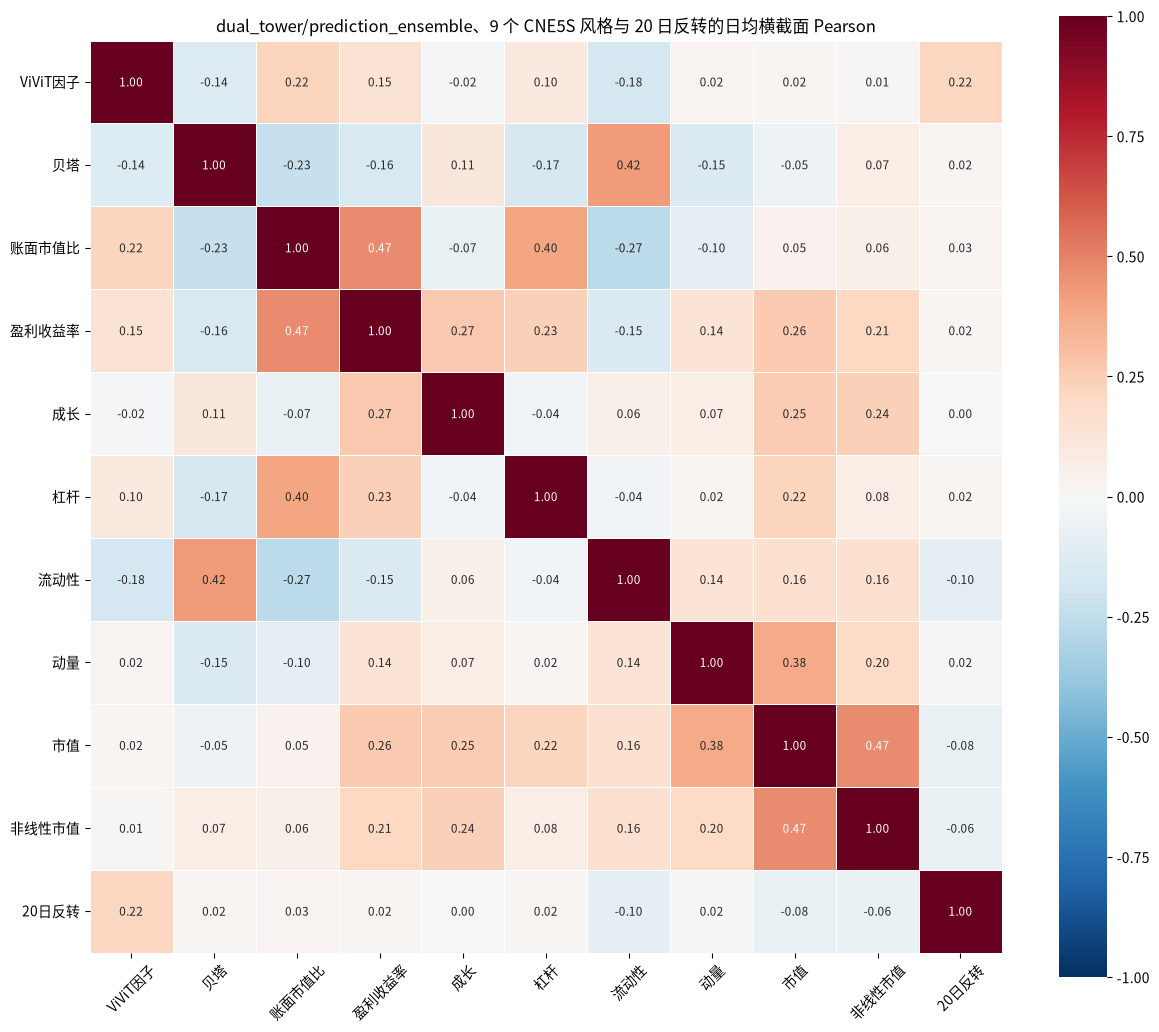

In [3]:
from pathlib import Path
from matplotlib import font_manager
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

print(f"{SOURCE_RUN_NAME}/{SOURCE_PREDICTION_COLUMN} 对 10 个风险变量的全样本日均 Pearson")
display(analysis["correlation_summary"])
print("逐年日均 Pearson")
display(analysis["annual_correlations"])
matrix_for_heatmap = (
    analysis["correlation_matrix_summary"]
    .pivot(index="row_name", columns="column_name", values="mean_pearson")
    .loc[list(MATRIX_COLUMNS), list(MATRIX_COLUMNS)]
)
matrix_for_heatmap.index = [
    MATRIX_LABELS[name] for name in MATRIX_COLUMNS
]
matrix_for_heatmap.columns = [
    MATRIX_LABELS[name] for name in MATRIX_COLUMNS
]

CJK_FONT_PATH = Path.home() / ".local/share/fonts/NotoSansCJKsc-Regular.otf"
if CJK_FONT_PATH.exists():
    font_manager.fontManager.addfont(str(CJK_FONT_PATH))
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK SC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

figure, axis = plt.subplots(figsize=(12.5, 10.5))
sns.heatmap(
    matrix_for_heatmap, ax=axis, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", square=True, linewidths=0.5,
    linecolor="white", cbar=True, annot_kws={"fontsize": 8.5},
)
axis.set_title(
    f"{SOURCE_RUN_NAME}/{SOURCE_PREDICTION_COLUMN}、"
    "9 个 CNE5S 风格与 20 日反转的日均横截面 Pearson"
)
axis.set_xlabel("")
axis.set_ylabel("")
axis.tick_params(axis="x", rotation=45)
axis.tick_params(axis="y", rotation=0)
figure.tight_layout()
display(figure)
plt.close(figure)


## 相关性的时间序列：持续暴露还是周期暴露

该图同样在残差生成之前绘制，信号列仍由 `SOURCE_PREDICTION_COLUMN` 指定。将 9 个 CNE5S 风格和 20 日反转放在一张 5×2 子图中，不做滚动平滑；曲线长期保持同一符号表示暴露较持续，围绕零轴反复切换则更接近周期性暴露。


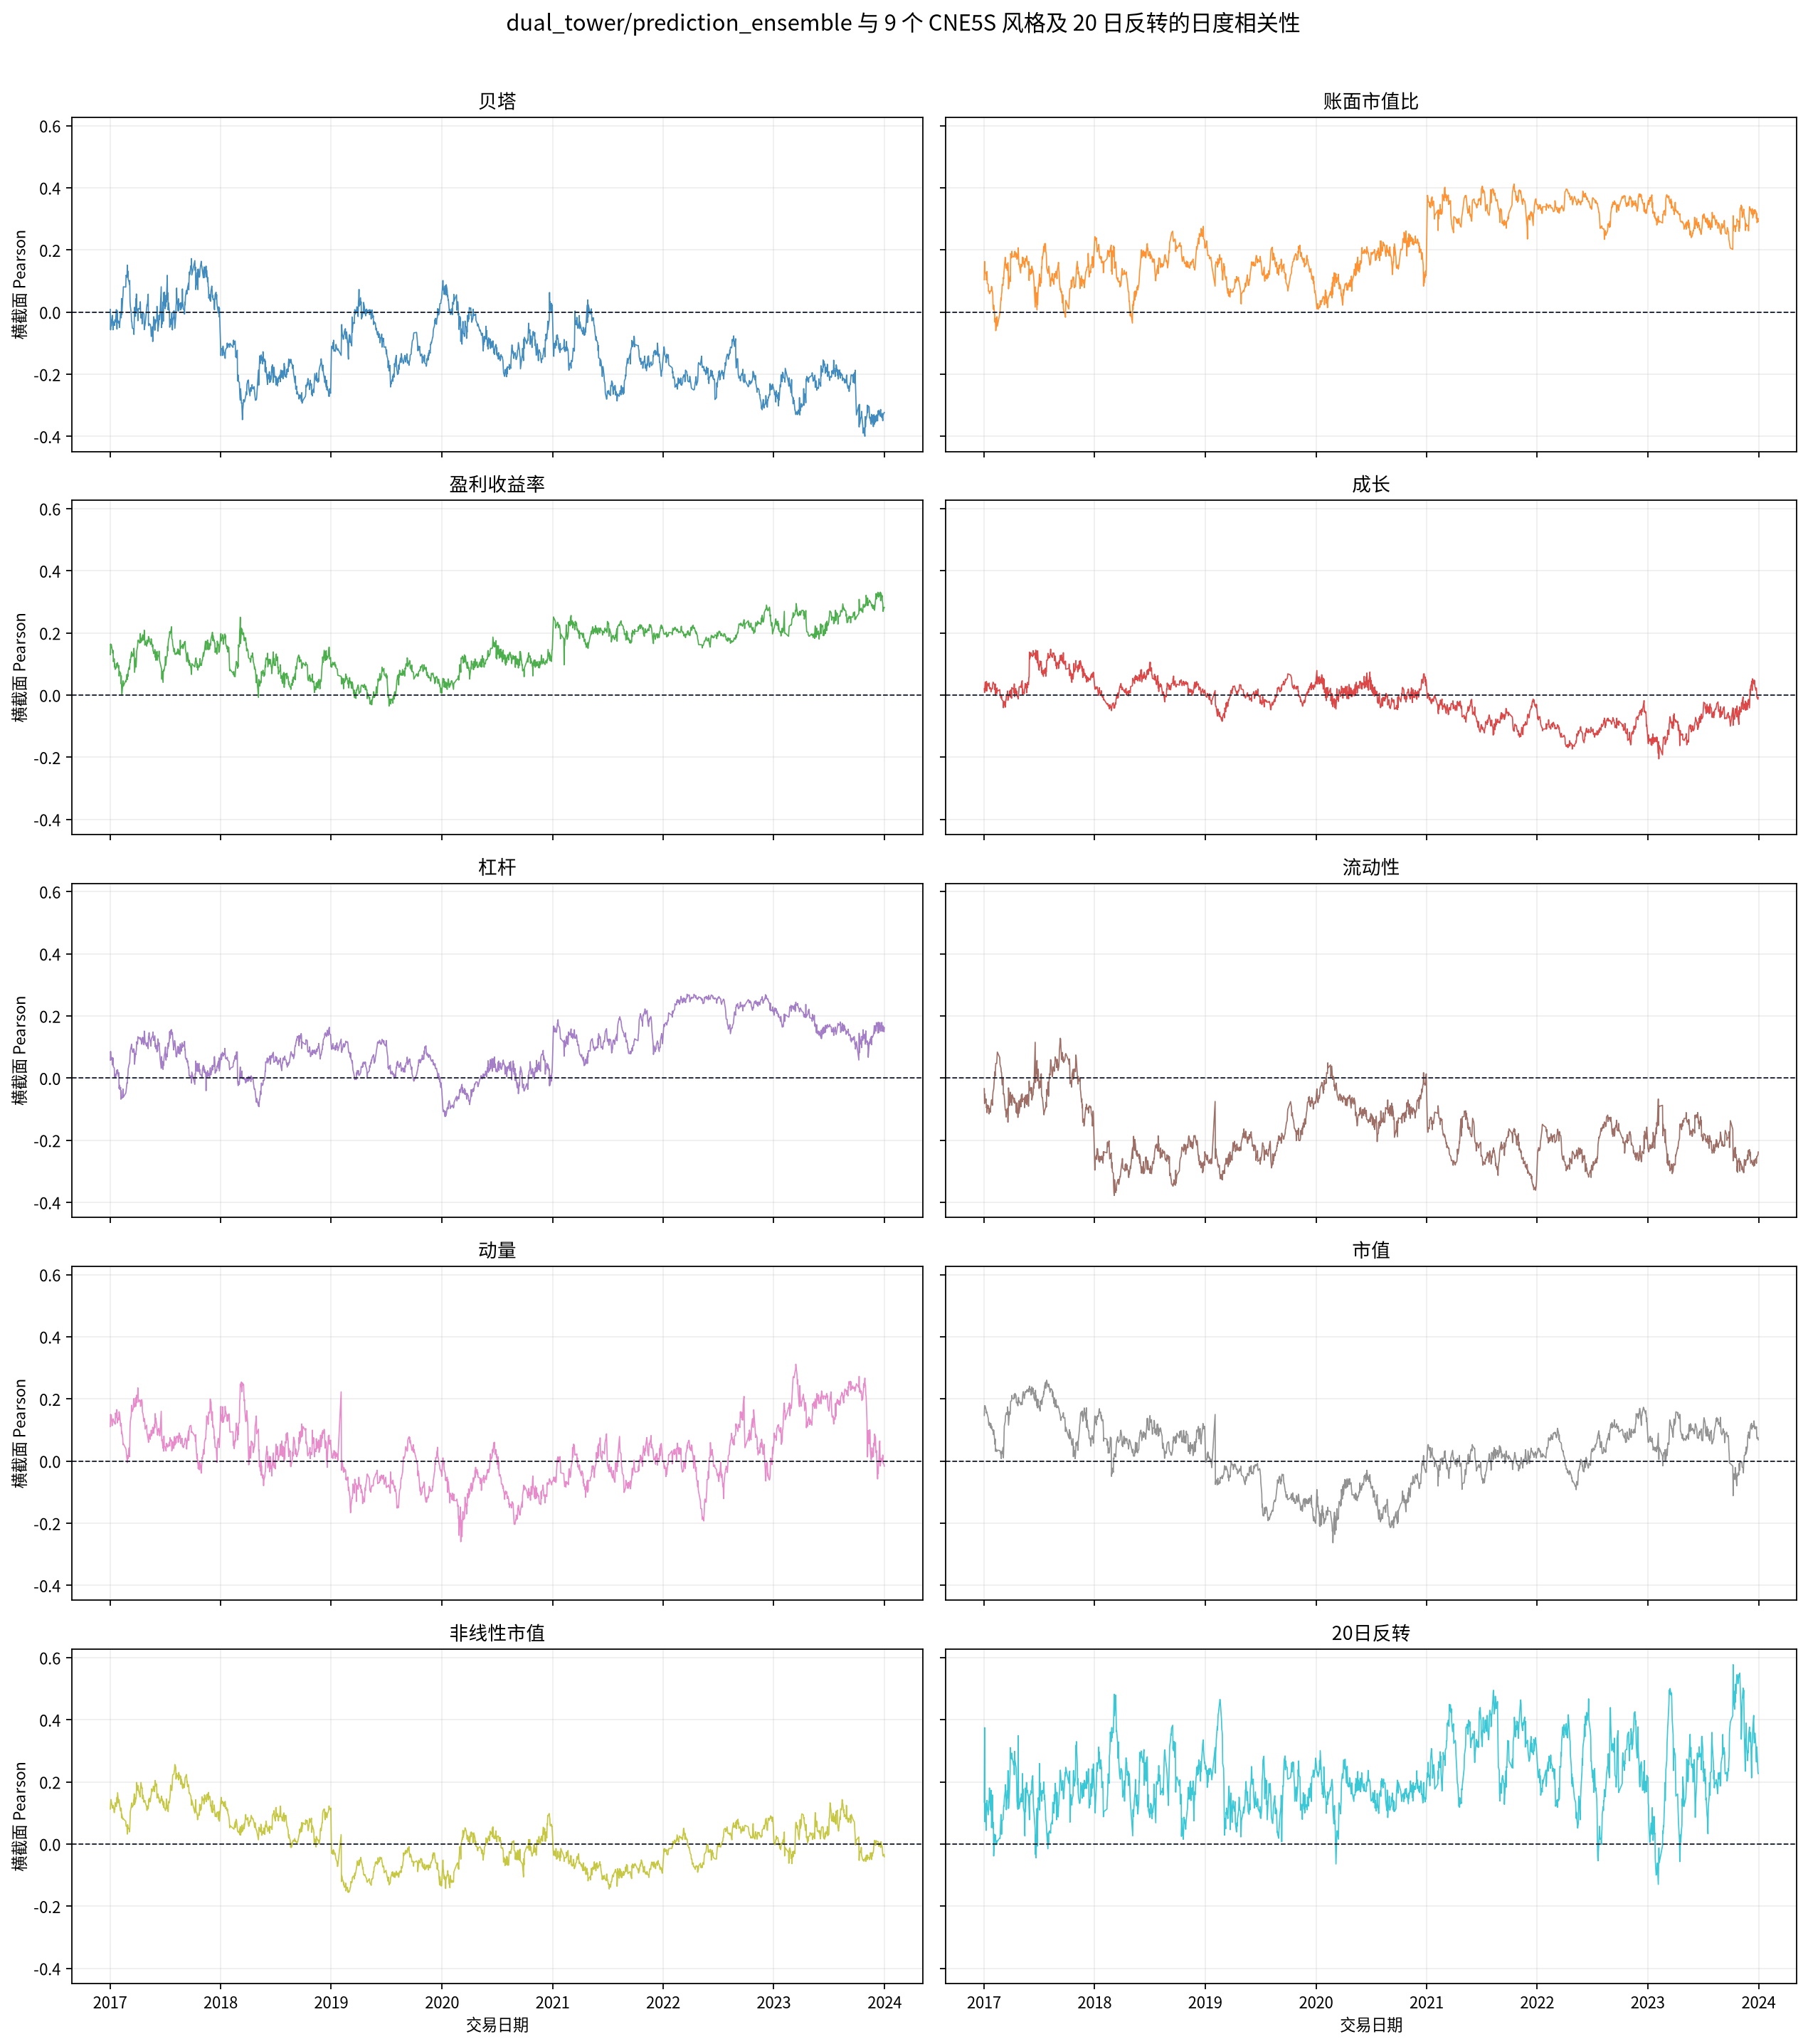

In [4]:
from io import BytesIO
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image as NotebookImage, display

correlation_ts = analysis["daily_correlations"].copy()
correlation_ts["trade_date"] = pd.to_datetime(
    correlation_ts["trade_date"], format="%Y%m%d"
)
correlation_ts.sort_values(["factor_name", "trade_date"], inplace=True)

figure, axes = plt.subplots(
    5, 2, figsize=(16, 18), sharex=True, sharey=True
)
colors = plt.get_cmap("tab10").colors
for axis, color, factor_name in zip(
    axes.flat, colors, CORRELATION_COLUMNS
):
    daily = correlation_ts.loc[
        correlation_ts["factor_name"].eq(factor_name)
    ]
    axis.plot(
        daily["trade_date"], daily["pearson"],
        color=color, linewidth=0.75, alpha=0.85,
    )
    axis.axhline(0.0, color="#111827", linewidth=0.8, linestyle="--")
    axis.set_title(STYLE_LABELS[factor_name])
    axis.grid(alpha=0.2)

for axis in axes[-1, :]:
    axis.set_xlabel("交易日期")
for axis in axes[:, 0]:
    axis.set_ylabel("横截面 Pearson")
figure.suptitle(
    f"{SOURCE_RUN_NAME}/{SOURCE_PREDICTION_COLUMN} 与 9 个 CNE5S 风格"
    "及 20 日反转的日度相关性",
    fontsize=14, y=0.995,
)
figure.tight_layout(rect=(0, 0, 1, 0.985))
image_buffer = BytesIO()
figure.savefig(image_buffer, format="png", dpi=160, bbox_inches="tight")
plt.close(figure)
display(NotebookImage(data=image_buffer.getvalue()))


## 步骤 4：按开关生成残差；步骤 5：仅对已生成残差做正交性验收

当 `GENERATE_RESIDUAL_RUN=False` 时，本单元明确跳过构建和验收，现有同名残差 run 及其 Notebook03 回测产物保持不变。

当开关为 `True` 时，对 `SOURCE_PREDICTION_COLUMN` 指定的源信号，以行业固定效应和 10 个风险连续变量做每日等权 OLS。反转有效值按 `ddof=0` 标准化，价格缺失填中性值 0；未匹配 CNE5S 的股票进入 UNKNOWN 行业。构建完成后才检验残差与十个连续变量及行业的正交性，并给出 Notebook03 配置。


In [5]:
result = None

if not GENERATE_RESIDUAL_RUN:
    print({
        "状态": "已完成源因子覆盖、相关性与绘图；按开关跳过残差生成",
        "修改残差run": False,
        "修改既有回测产物": False,
        "如需生成": "将 GENERATE_RESIDUAL_RUN 改为 True 后重新运行本单元",
    })
else:
    from stage09_barra_postprocess import build_barra_residual_run

    result = build_barra_residual_run(
        source_run_name=SOURCE_RUN_NAME,
        residual_run_name=RESIDUAL_RUN_NAME,
        cne5s_path=CNE5S_PATH,
        vivit_data_root=VIVIT_DATA_ROOT,
        minimum_match_rate=MINIMUM_MATCH_RATE,
        eod_path=EOD_PATH,
        calendar_path=CALENDAR_PATH,
        overwrite_existing=OVERWRITE_EXISTING_DERIVED_RUN,
        source_factor_column=SOURCE_PREDICTION_COLUMN,
    )
    print({
        "源预测列": result["source_factor_column"],
        "复用已有同签名产物": result["reused"],
        "本次已替换旧派生run": result["overwritten"],
    })

    diagnostics = result["regression_diagnostics"]
    display(diagnostics.groupby("year", as_index=False).agg(
        dates=("trade_date", "nunique"),
        rows=("rows", "sum"),
        mean_barra_match_rate=("match_rate", "mean"),
        mean_reversal_coverage=("reversal_coverage", "mean"),
        min_rank=("matrix_rank", "min"),
        max_condition_number=("condition_number", "max"),
        mean_r_squared=("r_squared", "mean"),
        max_ten_factor_residual_corr=(
            "max_abs_style_residual_corr", "max"
        ),
        max_industry_residual_mean=(
            "max_abs_industry_residual_mean", "max"
        ),
    ))

    print({
        "派生预测目录": str(result["prediction_root"]),
        "Barra与反转分析目录": str(result["neutralization_root"]),
        "lineage manifest": str(result["manifest_path"]),
        "必须重新运行Notebook03": not result["reused"],
        "Notebook03配置": {
            "FOLDER_NAME": RESIDUAL_RUN_NAME,
            "PREDICTION_COLUMN": "prediction_ensemble",
            "BASELINE_RUN_NAME": SOURCE_RUN_NAME,
            "BASELINE_PREDICTION_COLUMN": SOURCE_PREDICTION_COLUMN,
            "BACKTEST_MODE": "mode2_t_no_filter",
        },
    })


{'源预测列': 'prediction_ensemble', '复用已有同签名产物': False, '本次已替换旧派生run': False}


,year,dates,rows,mean_barra_match_rate,mean_reversal_coverage,min_rank,max_condition_number,mean_r_squared,max_ten_factor_residual_corr,max_industry_residual_mean
0,2018,243,796559,0.999970,0.998439,10,3.102337,0.121964,1.382627e-15,5.292255e-16
1,2019,244,861870,0.999944,0.996962,10,2.728875,0.211770,2.320167e-15,4.933654e-16
2,2020,243,916587,0.999742,0.993385,10,3.192455,0.124817,1.075667e-15,5.921189e-16
3,2021,242,1027544,0.999634,0.991459,10,3.243424,0.085693,7.588653e-16,5.536845e-16
4,2022,242,1120684,0.999728,0.994237,10,2.639841,0.292097,1.837767e-15,7.190016e-16
5,2023,242,1195010,0.999818,0.996085,10,2.488649,0.090363,8.097963e-16,3.773437e-16
6,2024,242,1200893,0.999935,0.998707,10,4.196719,0.206385,1.901206e-15,5.343131e-16


{'派生预测目录': '/root/autodl-tmp/ViViT/data/predictions/runs/dual_tower_barra_residual', 'Barra与反转分析目录': '/root/autodl-tmp/ViViT/data/quality/runs/dual_tower_barra_residual/barra_neutralization', 'lineage manifest': '/root/autodl-tmp/ViViT/data/quality/runs/dual_tower_barra_residual/barra_neutralization/neutralization_manifest.json', '必须重新运行Notebook03': True, 'Notebook03配置': {'FOLDER_NAME': 'dual_tower_barra_residual', 'PREDICTION_COLUMN': 'prediction_ensemble', 'BASELINE_RUN_NAME': 'dual_tower', 'BASELINE_PREDICTION_COLUMN': 'prediction_ensemble', 'BACKTEST_MODE': 'mode2_t_no_filter'}}
